# Lab 3 — Discrete Fourier Transforms

The lab consists of four questions exploring various aspects of discrete time signals. We will cover:

1. **Sampling:** The construction of discrete time signals through samples of a continuous time signal. 
2. **DFT:** The computation of the Discrete Fourier Transform (DFT) of discrete time signals and its properties
3. **Computational Costs:** The computational cost (runtime) of computing a DFT and an illustration of how to speed it up
4. **Filtering:** Using the DFT to design systems capable of denoising corrupted signals and illustrate the principles of radio transmission.

Each of these modules has already been implemented. Run the code and record your observations in the cell following the question.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import lab_tools as lab
%matplotlib inline

## Q1 — Sampling
### 1A. How are samples obtained?

Here, let's consider the real-valued continuous-time signal defined below
$$x_c(t)=\cos(2\pi f_0t)$$
where $f_0$ is the frequency in hertz (cycles per second)

We will sample the signal $x_c (t)$ at a sampling frequency of $f_s$ (measured in samples per second). Therefore, each sample is spaced $T_s = 1 / f_s$ seconds apart. The output of the sampling process is the discrete sequence defined below:
$$x[n]=x_c(nT_s),\qquad n=0,1,2,\ldots.$$

Run the code below. The smooth curve shows the known continuous signal while the separate stem plot below shows the sampled signal. Then change only `f_s` to **32**, then **8**. Predict how many observations fit in one second. Restore **16** afterward.

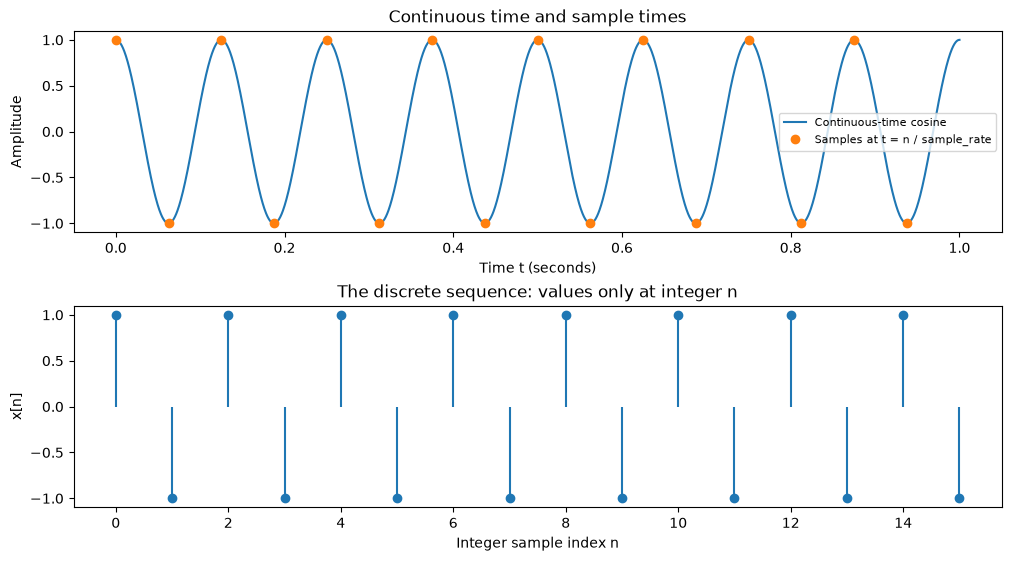

In [2]:
f_0 = 8       # Hz
f_s = 16      # Samples per second
duration = 1  # How long to plot the signal
sample_n, samples = lab.sampling_view(f_0, f_s, duration)

**1A Observations**

The number of observations in one second is exactly $f_s$ (samples are at $t = n/f_s$, $n = 0,\dots,f_s-1$).

| $f_s$ | samples in 1 s | samples per cycle of the 8 Hz cosine | what $x[n]$ looks like |
|---|---|---|---|
| 32 | 32 | 4 | $1, 0, -1, 0, 1, \dots$ — clearly a cosine |
| 16 | 16 | 2 | $1, -1, 1, -1, \dots$ — only the peaks and troughs; the bare minimum |
| 8 | 8 | 1 | $1, 1, 1, \dots$ — every sample lands on a peak, so it looks like a **constant (0 Hz)** |

- Raising $f_s$ gives a denser, more faithful picture of the continuous signal.
- At $f_s = 16 = 2f_0$ we are exactly at the Nyquist rate: the alternating sequence is the fastest a discrete signal can oscillate ($\Omega = \pi$ rad/sample).
- At $f_s = 8$ the 8 Hz cosine is indistinguishable from DC — a preview of **aliasing** (1B).
- The discrete sequence $x[n]$ only knows the integer index $n$; the sampling rate is information we have to remember separately.

### 1B. Aliasing - When does sampling lose the original signal?
**Aliasing** occurs when different continuous signals result in the same discrete signal after sampling. Compare two cosine signals at **3 Hz** and **13 Hz**.

Run the cell at **16 samples/second**. Compare the continuous time plots in the first figure and the actual sample values obtained after sampling the two signals. Then change only `alias_sample_rate` to **32** and check if the pattern persists.

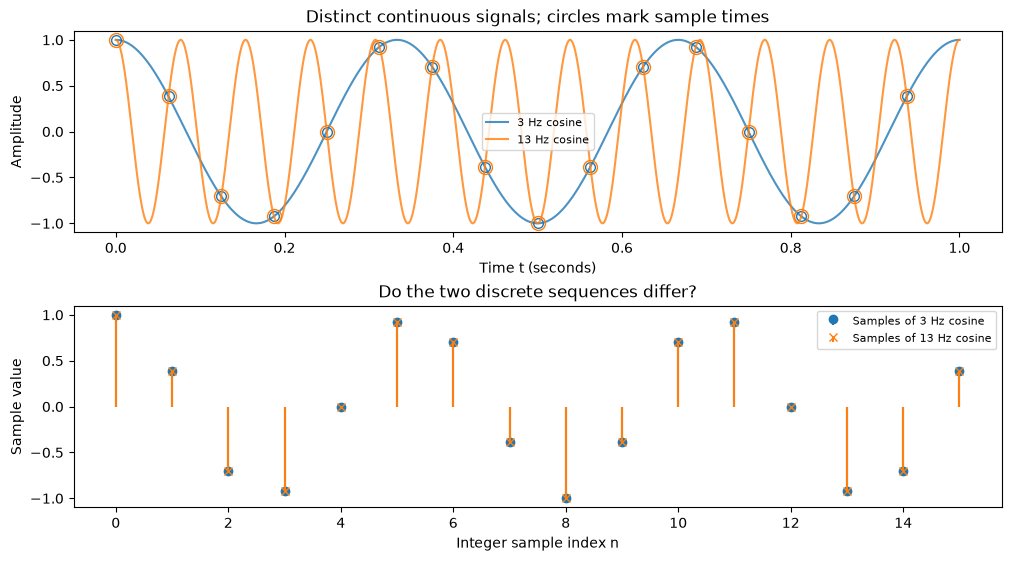

In [3]:
alias_sample_rate = 16   # EXPERIMENT: then use 32
samples_a, samples_b = lab.aliasing_view(
    frequency=3, alias_frequency=13, sample_rate=alias_sample_rate, duration=1
)

**1B Questions**
- Are the two cosines at 3Hz and 13Hz distinguishable when sampled at 16Hz?
- Which other frequencies alias with the 3Hz cosine when sampled at 16Hz?
- At which sampling frequency would the 3Hz cosine be distinguishable from *all* signals bandlimited to 13Hz? 

**1B Answers**

- **No.** At $f_s=16$ the 3 Hz and 13 Hz cosines produce *identical* samples (max difference $\approx 10^{-14}$, i.e. floating-point round-off). Because $13 = 16 - 3$:
  $\cos(2\pi\cdot 13\,n/16) = \cos(2\pi n - 2\pi\cdot 3\,n/16) = \cos(2\pi\cdot 3\,n/16)$.
  At $f_s = 32$ the samples differ (max difference $\approx 1.96$), so the pattern does **not** persist.
- **Aliases of 3 Hz at $f_s=16$:** every $f = |\pm 3 + 16m|$ for integer $m$, i.e. **3, 13, 19, 29, 35, 45, 51, …** Hz (checked numerically for 0–59 Hz). Adding a whole multiple of $f_s$ adds a whole number of $2\pi$ per sample, and the cosine is even so $-3$ Hz looks like $+3$ Hz.
- **Any $f_s > 26$ Hz** (strictly greater than $2 \times 13$, the Nyquist rate). Then every alias $|\pm 3 + mf_s|$ with $m \ne 0$ is above 13 Hz, and, more generally, *every* signal bandlimited to 13 Hz has its own unique samples (sampling theorem). At exactly 26 Hz it fails: e.g. $\sin(2\pi\cdot 13 t)$ samples to all zeros, so $\cos(2\pi 3t)$ and $\cos(2\pi 3t) + \sin(2\pi 13t)$ give the same samples.

### 1C. Does sampling a periodic continuous signal yield a periodic discrete signal?
Recall that our sampled cosine satisfies:

$$
    x[n] = \cos \left(2\pi \frac{f_0}{f_s} n\right)
$$

where $f_0$ is the frequency of the continuous cosine and $f_s$ is the sampling frequency. Try changing the value of $f_0$ and describe whether the sampled signal is periodic. If it is periodic, compute its period.

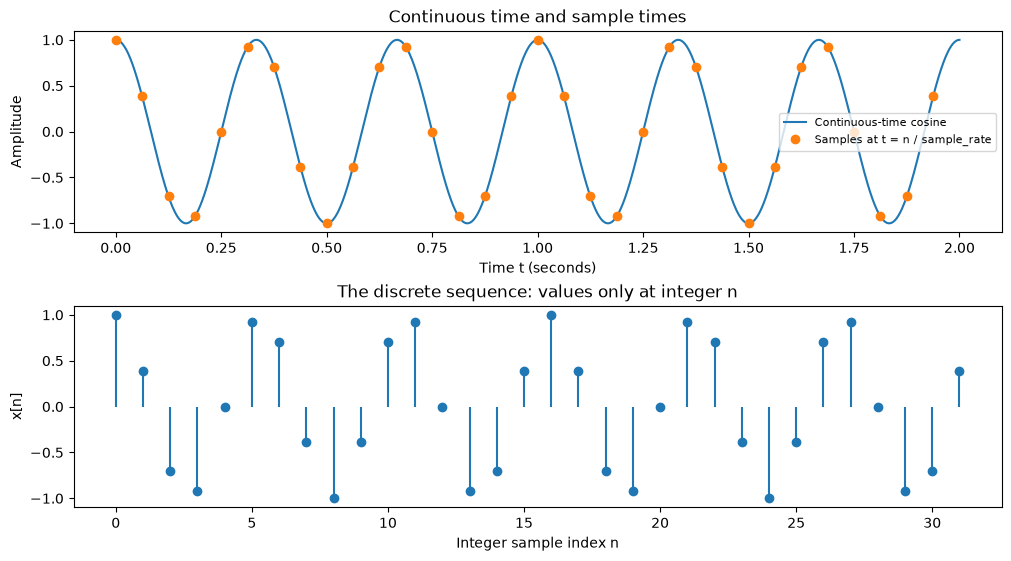

In [4]:
f0 = 3   # EXPERIMENT: then use 4
period_n, period_samples = lab.sampling_view(
    frequency = f0, sample_rate = 16, duration=2
)

**1C observations**
- What is the period for $f_0 = 3\text{Hz}$?
- What about when $f_0 = 4\text{Hz}$?
- In both these cases, the sampled signal was periodic. Describe an $f_0$ for which the sampled signal is _not_ periodic?

**1C Observations**

The sampled cosine is $x[n]=\cos(2\pi \tfrac{f_0}{f_s} n)$. It is periodic with period $N$ iff $\tfrac{f_0}{f_s}N$ is an integer, so **the smallest period is the denominator of $f_0/f_s$ written in lowest terms.**

- $f_0 = 3$ Hz: $f_0/f_s = 3/16$ (already in lowest terms) → **period $N = 16$ samples** (it fits 3 full cycles in 16 samples). Note this is *not* the continuous period $f_s/f_0 = 5.33$ samples, which is not an integer.
- $f_0 = 4$ Hz: $4/16 = 1/4$ → **period $N = 4$ samples** (one cycle every 4 samples).
- **Not periodic:** any $f_0$ with $f_0/f_s$ irrational, e.g. $f_0 = \sqrt{2}$ Hz or $f_0 = \pi$ Hz. Then $\tfrac{f_0}{f_s}N$ is never an integer, so the samples never repeat even though the continuous cosine is periodic. (Careful: $f_0 = 3.3$ Hz *is* periodic, with $3.3/16 = 33/160$ → period 160, just a long one.)

## Q2 — DFT
For this question, we will assume that a discrete time signal has already been obtained, either by sampling a continuous signal or through some other means. We will compute DFTs of the following discrete-time signals (with $N = 64$):
$$x[n]=A\cos(2\pi c n/N+\phi),\qquad n=0,\ldots,N-1.$$
where $A$ is amplitude, $c$ is the number of cycles across $N$ samples, and $\phi$ is the phase.

**Default Settings:** To restore default settings, set `N=64`, `amplitude=1.0`, `cycles=5`, and `phase=0.0`, then rerun the cell.

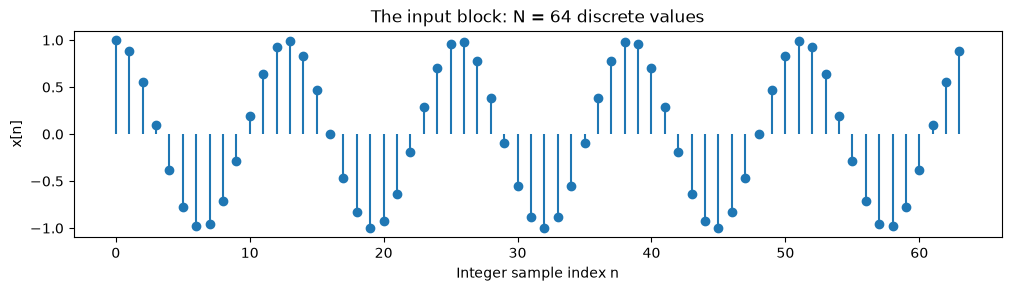

In [5]:
N = 64
amplitude = 1.0
cycles = 5
phase = 0.0
n = np.arange(N)
x = amplitude * np.cos(2 * np.pi * cycles * n / N + phase)
lab.dft_signal(x)

### 2A. Computing the DFT
Recall from the lecture that the **discrete Fourier transform (DFT)** expresses $x$ in an alternative basis with the coefficients defined by the analysis equations below:
$$X[k]=\sum_{n=0}^{N-1}x[n]e^{-j2\pi kn/N},\qquad k=0,\ldots,N-1.$$
The integer $k$ corresponds to the coefficient of the basis vector with angular frequency $2\pi k / N$ radians/sample.

Run the next cell. The plot uses signed angular frequencies in radians per sample, from $-\pi$ to $\pi$ (recall that the basis vectors with frequency $\Omega$ and $2\pi + \Omega$ are the same).

Locate the two peaks. Change the `amplitude` and `phase` and observe what happens.

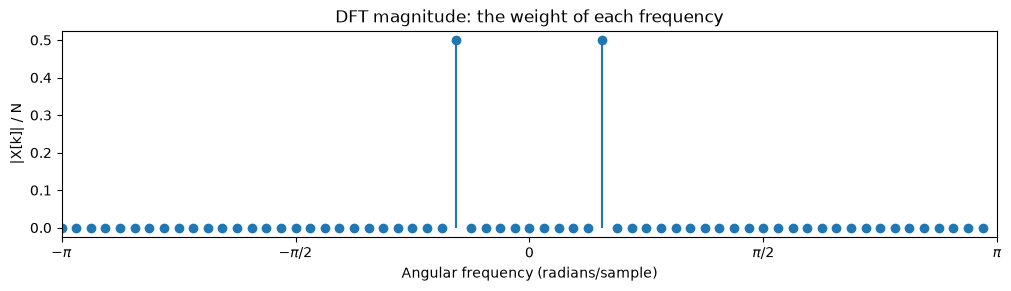

In [6]:
X = lab.dft_magnitude(x)

**2A Questions**
- For the default settings, what are the frequencies whose DFT values have the largest magnitude?
- How does the DFT magnitude plot change when **non-integer** values of cycles are used?

<details>
In fact, this phenomenon is known as **spectral leakage** where the chosen block does not align with the period of the input signal.
</details>

**2A Answers**

- **Default ($c=5$):** the only nonzero coefficients are at $k = \pm 5$, i.e. angular frequencies $\Omega = \pm 2\pi\cdot 5/64 = \pm 5\pi/32 \approx \pm 0.49$ rad/sample. Each has $|X[k]|/N = A/2 = 0.5$, because $A\cos(\Omega n) = \tfrac{A}{2}e^{j\Omega n} + \tfrac{A}{2}e^{-j\Omega n}$ (Euler) — half the amplitude at $+\Omega$, half at $-\Omega$. Every other bin is zero (to round-off).
  - Changing the **amplitude** scales both peaks linearly ($A = 2$ → peaks of 1.0). The DFT is linear.
  - Changing the **phase** does *not* change the magnitude plot at all — phase lives in the angle of $X[k]$ (see 2B).
- **Non-integer cycles** (e.g. $c = 5.5$ or $5.25$): the two clean spikes are replaced by a smeared spectrum. The peak is lower and split across the neighbouring bins ($c=5.5$: $|X|/N \approx 0.33$ at $k=\pm 6$ and $0.30$ at $k=\pm5$), and **all 64 bins** become nonzero, decaying away from the true frequency. This is **spectral leakage**: the DFT only has basis frequencies $2\pi k/N$ with integer $k$, and the block does not contain a whole number of cycles, so the signal's energy has to be spread over many basis vectors to represent it.

### 2B. The Phase (Argument) of the DFT Coefficients
We will now plot the **phase** or **argument** of the DFT coefficients.

Run the next cell at the baseline settings. Then set `phase=np.pi/2` in the baseline cell and rerun the experiment.

Note that phases are numerically unstable to compute for small complex numbers. Consequently, they are only plotted for larger DFT coefficients. 

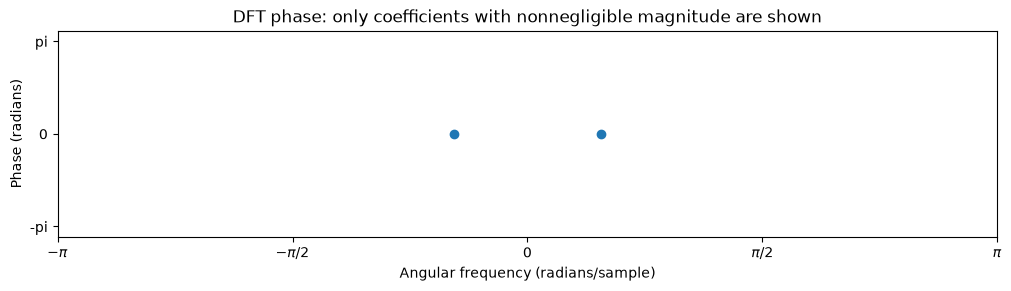

In [7]:
X = lab.dft_phase(x)

**2B Questions**
- What do you observe about the phases of the positive and negative frequencies? 
- Are the phases of the positive and negative frequencies related in any way?
- How does changing the initial phase affect the phase of the DFT coefficients?

**2B Answers**

- **Baseline ($\phi=0$):** both coefficients ($k=\pm5$) have phase 0.
  **$\phi=\pi/2$:** the $+5$ coefficient has phase $+\pi/2$ and the $-5$ coefficient has phase $-\pi/2$. The positive- and negative-frequency phases are always **equal in size and opposite in sign**.
- **Yes — they are complex conjugates:** $X[-k] = X[N-k] = X[k]^*$, so $|X[-k]| = |X[k]|$ and $\angle X[-k] = -\angle X[k]$. This **conjugate symmetry** holds for *every real-valued* signal, because the imaginary parts of $e^{+j\Omega n}$ and $e^{-j\Omega n}$ must cancel to leave a real signal. (Practical consequence: for real signals the negative half of the DFT is redundant, which is why `np.fft.rfft` exists.)
- **The initial phase appears directly as the DFT phase:** $A\cos(\Omega n + \phi) = \tfrac{A}{2}e^{j\phi}e^{j\Omega n} + \tfrac{A}{2}e^{-j\phi}e^{-j\Omega n}$, so $X[5] = \tfrac{NA}{2}e^{j\phi}$ and $X[-5] = \tfrac{NA}{2}e^{-j\phi}$. Setting $\phi = 1$ rad gave phases of exactly $+1$ and $-1$. Phase shifts the angle; magnitude is unchanged. Magnitude says *how much* of each frequency, phase says *where in its cycle* it starts.

### 2C. Inverting the DFT coefficients
The **inverse DFT** utilizes the synthesis equation to recover the input signal:
$$x[n]=\frac{1}{N}\sum_{k=0}^{N-1}X[k]e^{+j2\pi kn/N},\qquad 0\leq n<N.$$
The corresponding NumPy function `np.fft.ifft(X)` evaluates this inverse for those $N$ positions.

In the lecture, we constructed the DTFS by evaluating the above formula outside [0, ..., N - 1]. Run the next cell to see what the formula yields for the samples from $[-N, ..., 2 * N - 1]$ (this covers three blocks).

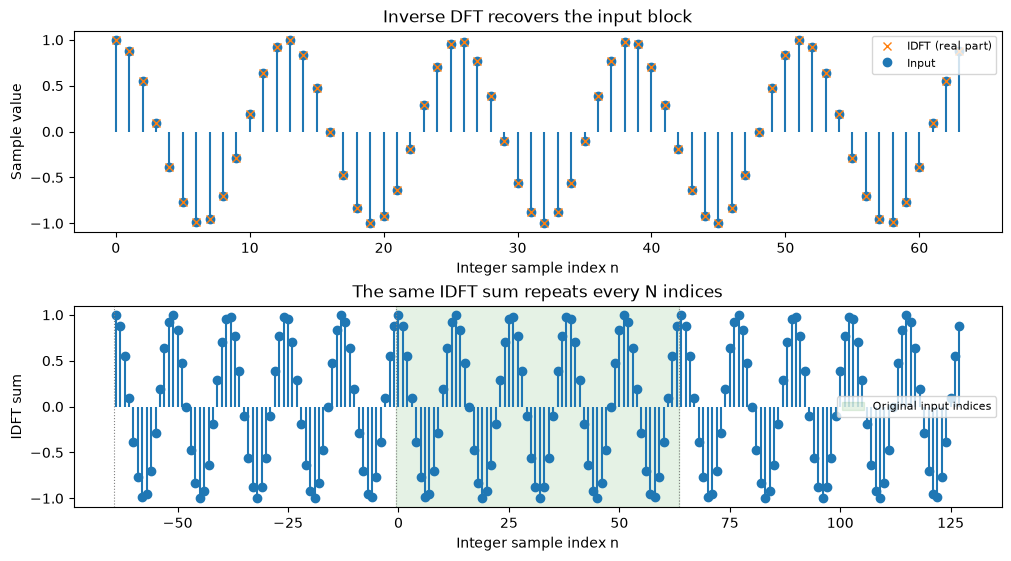

In [8]:
# Invert the current DFT and display its periodic extension.
X = np.fft.fft(x)
x_reconstructed = np.fft.ifft(X)
extended_n, extended_x = lab.dft_reconstruction(x, periods=3)

**2C Questions:**
- Does the IDFT (synthesis equation) recover the original signal in the input block (The 64 indices from 0 to 63)? 
- What happens outside the block?
- Change the number of cycles to 0.5 and observe what happens? Does it still recover the input signal?

**2C Answers**

- **Yes.** Inside the block $0 \le n \le 63$ the IDFT equals the input to machine precision (max error $\approx 3\times10^{-16}$). The DFT is an invertible change of basis — no information is lost.
- **Outside the block** the synthesis sum simply **repeats the block every $N=64$ samples**: $x[n+N] = x[n]$ (checked to $\approx 10^{-14}$). This has to happen because every basis vector satisfies $e^{j2\pi k(n+N)/N} = e^{j2\pi kn/N}$. The DFT therefore implicitly treats the block as **one period of a periodic signal** — this periodic extension is the DTFS from the lecture. For $c=5$ (a whole number of cycles) the repetition joins smoothly and looks like the true cosine continuing.
- **$c = 0.5$:** inside the block it **still recovers the input perfectly** (error $\approx 4\times10^{-16}$). But outside, the extension is the half-cycle copied over and over, so there is a **jump** at every block edge ($x[63] \approx -1$, then the extension restarts at $x[64] = 1$), instead of the true continuation $\cos(\pi n/64)$ which would keep going down to $-1$ and come back up. The DFT cannot know what the signal does outside the block; it assumes periodicity. That artificial discontinuity is exactly what causes the **spectral leakage** seen in 2A.

## Q3: How long does it take to compute a DFT?

### 3A. Computing the DFT by Computing the Analysis Matrix

The method we discussed in class constructs the $N\times N$ matrix:
$$W_{k,n}=e^{-j2\pi kn/N},\qquad X=Wx.$$
The **fast Fourier transform (FFT)** is a much faster algorithm to compute the same coefficients. The code below implements the simple algorithm. We'll compare its runtime with the FFT below.

The code below computes the DFT by explicitly computing the matrix $W$ and performing the multiplication. 

**Optional:** Read the code to understand how it works.

In [9]:
def dense_dft(x):
    """Compute the DFT by constructing its matrix and multiplying by x."""
    N = len(x)
    k = np.arange(N)[:, None]
    n = np.arange(N)[None, :]
    exponent = - ((2 * np.pi * k * n) / N) * 1j
    W = np.exp(exponent)
    return W @ x

### 3B. Measure and predict computation time
Compare the dense DFT and FFT over different input sizes $N$. Edit `benchmark_sizes` below, using integers greater than 1. The output contains three plots:

1. **Measured runtimes:** elapsed seconds per transform, including matrix construction and multiplication for the dense DFT.
2. **Predicted runtimes:** the growth models $T_{\mathrm{dense}}(N)=aN^2$ and $T_{\mathrm{FFT}}(N)=bN\log_2N$, where $a$ and $b$ are separate timing constants for this machine.
3. **Measured runtime ratio:** $T_{\mathrm{dense}}(N)/T_{\mathrm{FFT}}(N)$. A ratio of 100 means the dense DFT took 100 times as long as the FFT.

Growth formulas alone do not give seconds. To set $a$ and $b$, use each measured time at the largest tested size $N_0$. The predictions are
$$\widehat T_{\mathrm{dense}}(N)=T_{\mathrm{dense}}(N_0)\left(\frac{N}{N_0}\right)^2,\qquad
\widehat T_{\mathrm{FFT}}(N)=T_{\mathrm{FFT}}(N_0)\frac{N\log_2N}{N_0\log_2N_0}.$$
The predictions match the measurements at $N_0$ by construction. Elsewhere, overhead, cache effects and timing noise can cause differences. Compare the growth trends rather than expecting exact agreement.

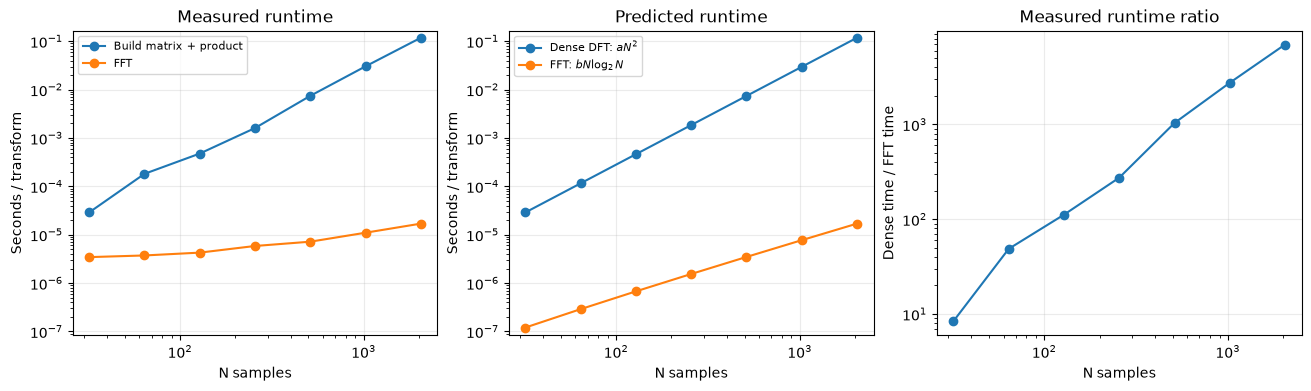

In [10]:
benchmark_sizes = [32, 64, 128, 256, 512, 1024, 2048]  # EXPERIMENT: edit this list
measured_sizes, times = lab.benchmark(dense_dft, sizes=benchmark_sizes)

**3B Questions**
- What do you observe as $N$ grows?
- Does the gap between the two algorithms increase or decrease as $N$ grows larger?

**3B Answers** (measured on a Windows laptop; the dense DFT was first checked against `np.fft.fft` — identical to $\sim10^{-12}$)

| $N$ | dense DFT | FFT | dense / FFT |
|---|---|---|---|
| 32 | 32 µs | 3.7 µs | 8.6× |
| 128 | 0.44 ms | 4.9 µs | 90× |
| 512 | 8.5 ms | 7.2 µs | 1 179× |
| 1024 | 32 ms | 12 µs | 2 712× |
| 2048 | 125 ms | 22 µs | 5 559× |

- **As $N$ grows**, the dense method's time grows roughly **4× per doubling of $N$** ($O(N^2)$: building the $N\times N$ matrix $W$ and doing $N^2$ multiply-adds), while the FFT grows only a little over **2× per doubling** ($O(N\log_2 N)$). The measured curves follow the predicted $aN^2$ and $bN\log_2N$ slopes on the log-log plot. At small $N$ the FFT is basically flat (~4 µs) because fixed call overhead dominates, so the predictions match less well there.
- **The gap increases.** The ratio is $\propto N^2/(N\log_2 N) = N/\log_2 N$, which grows without bound: ~9× at $N=32$ and ~5 600× at $N=2048$. For a 1-second, 48 kHz audio clip ($N=48\,000$) the dense approach would also need a $48\,000^2$ complex matrix ($\approx 37$ GB) — completely impractical. Both compute *exactly the same* coefficients; the FFT just reuses shared sub-computations (splitting into even/odd halves recursively).

## Q4: DFTs and Filtering
In this question, we'll explore some applications of DFTs for certain audio processing and transmission tasks.
### A. Audio denoising
Our first application will be audio denoising. Here, we are given an audio signal that has been corrupted by the addition of some high frequency noise. We will use the DFT to design a filter that can take the corrupted signal and largely recover the original clean signal. Our clean signal will be a two second audio signal consisting of two frequencies 220 and 440 Hz, sampled at $f_s=16000$ samples/second. This clean signal will then be corrupted by two high-frequency whistles at 3600 and 4100 Hz.

A **filter** modifies a signal by only allowing some frequency components through. A **bandpass** filter retains a range of frequencies while a **lowpass** keeps frequencies from zero up to a cutoff. The filter's **frequency response** $H$ will be 1 for frequencies we keep and 0 for those we remove. Recall that the output of a system is related to the input by $Y[k]=H[k]X[k]$. 

We will use a bandpass filter to recover our original inputs. In this example, the noise occupies higher frequencies than the wanted signal: the two input frequencies are at 220 Hz and 440 Hz while the added noise is at 3600 Hz and 4100 Hz. We will filter out the higher frequencies while retaining the smaller ones.

In the cells below, we define the clean and noisy signals and specify the bands of our bandpass filter. Run the two cells and visualize the frequency response of the bandpass filter. Which frequencies do we keep? Try changing the bands below and see what signals we retain. What if we only wanted to analyze the noise?

In [11]:
fs, clean, _, noisy = lab.audio_signals()
f = np.fft.fftfreq(len(noisy), 1 / fs)
low, high = 100, 1000

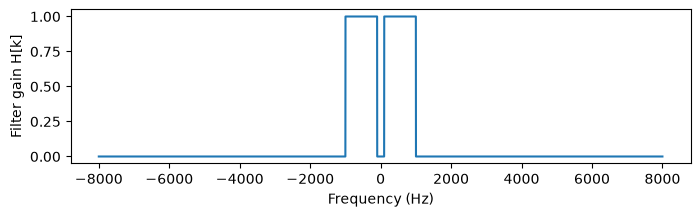

In [12]:
# Keep positive and negative frequencies whose magnitudes lie in the chosen band.
keep = (np.abs(f) >= low) & (np.abs(f) <= high)
plt.figure(figsize=(8, 2))
plt.plot(np.fft.fftshift(f), np.fft.fftshift(keep))
plt.xlabel("Frequency (Hz)")
plt.ylabel("Filter gain H[k]")
plt.show()

Next, apply the filters to our noisy input and check whether we recover the original input signals. Next, change the filter so we only recover the *noise* added to the signal. How should the bands of the bandpass filter change?

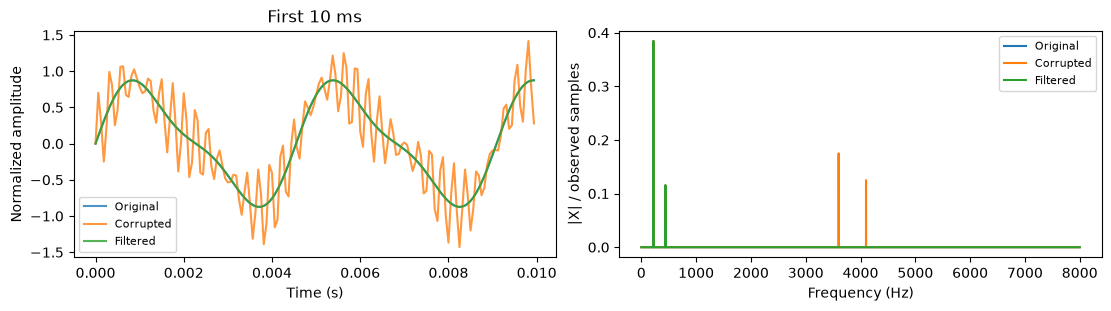

Original


Corrupted


Filtered


In [13]:
# Apply the filter, then compare the signals and listen.
filtered = np.fft.ifft(np.fft.fft(noisy) * keep).real
lab.audio_comparison({"Original": clean, "Corrupted": noisy, "Filtered": filtered}, fs)

**Q4A Questions**

- With the bandpass filter set to 100Hz - 1000Hz, what is recovered after the application of the filter?
- When the upper bound is reduced to 300Hz, what is lost in the input signal?
- Provide a frequency band for the bandpass filter which isolates the noise.

**Q4A Answers**

The filter keeps $|f|$ inside $[\text{low}, \text{high}]$ — note it keeps **both** the positive and negative frequencies (needed so the output stays real; see 2B conjugate symmetry).

- **100–1000 Hz:** passes the 220 Hz and 440 Hz tones and blocks the 3600/4100 Hz whistles. The output equals the **original clean signal** (max error $\approx 7\times10^{-13}$); it sounds like the clean tone with the whistle gone. It is this perfect because every tone is an exact DFT bin (whole cycles in the 2 s block), so there is no leakage.
- **Upper bound 300 Hz:** the **440 Hz component (the quieter, 0.3-amplitude overtone)** is also removed. Only the pure 220 Hz sine remains — same pitch, but a "thinner"/purer timbre. Error vs. the clean signal becomes $0.3/1.3 \approx 0.23$.
- **Isolating the noise:** any band that contains 3600 and 4100 Hz but not 220/440 Hz, e.g. **3000–5000 Hz** (or 3500–4500 Hz, or even 1000–8000 Hz). The output then equals `noisy - clean` to $\sim10^{-12}$ — just the whistle.

### B. Radio Transmission

How can two radio channels share one transmitted signal? In this exercise, we will implement a basic version of **Amplitude Modulation** (AM).

Suppose we have a signal $\cos (2\pi 100 t)$ we would like to transmit. The key idea is to multiply the signal by a higher-frequency **carrier signal**. After doing this, we get:
$$\cos(2\pi100t)\cos(2\pi4000t)
=\tfrac12\cos(2\pi4100t)+\tfrac12\cos(2\pi3900t).$$
These are two high-frequency signals centered at the carrier frequency of $4000$. We will then apply a bandpass filter around the carrier frequency to isolate the modulated channel. To transmit multiple signals, we will use multiple carrier frequencies and transmit the sum of the modulated signals. 

In this exercise, we will take two audio signals $x_1$ and $x_2$. We will provide each signal with its own carrier frequency $f_{c1}$ and $f_{c2}$. We will then transmit the combined signal:
$$
    f (t) = \cos(2\pi f_{c1}t) x_1 (t) + \cos(2\pi f_{c2}t) x_2 (t)
$$
If $|f_{c1} - f_{c2}|$ is much larger than the bandlimits of $x_1$ and $x_2$, we can recover the original signals. For instance, if both inputs have bandlimit $B$, using a bandpass filter with the band $f_{c1} - B, f_{c1} + B$, we recover: 
$$
    \cos(2\pi f_{c1}t) x_1 (t)
$$

In the cells below, we illustrate this principle with two audio signals that have been pre-prepared. First, run the next cell and listen to the two audio signals.

In [14]:
# Start with the bundled examples; change the filenames and labels for your own audio.
fs = 60000
audio_files = ["message1.wav", "message2.wav"]
audio_labels = ["Music", "Dialogue"]
messages = [lab.load_radio_audio(path, fs=fs, duration=5) for path in audio_files]
t = np.arange(len(messages[0])) / fs

lab.listen({audio_labels[0]: messages[0], audio_labels[1]: messages[1]}, fs)

Music


Dialogue


In the next cell, we've provided both the audio signals their own carrier frequencies of $12000\text{Hz}$ and $24000\text{Hz}$. We then multiply each signal by the carrier signal and visualize the updated Fourier coefficients. 

- What do you observe about the Fourier coefficients of the original signals? Do they overlap?
- What about after multiplying by the carrier signals?

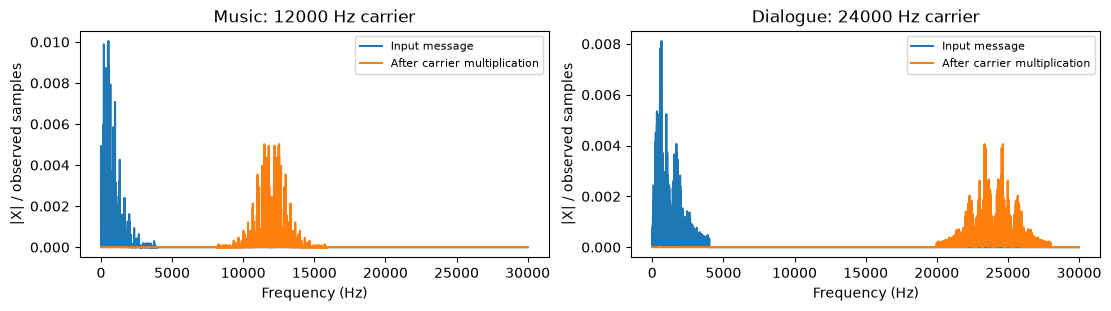

In [15]:
# Multiply each message by its carrier, then compare the spectra.
carrier_frequencies = (12000, 24000)  
carriers = [np.cos(2 * np.pi * fc * t) for fc in carrier_frequencies]
channels = [message * carrier for message, carrier in zip(messages, carriers)]
fig, axes = plt.subplots(1, 2, figsize=(11, 3), constrained_layout=True)
for j, ax in enumerate(axes):
    lab.spectrum(ax, messages[j], fs, "Input message")
    lab.spectrum(ax, channels[j], fs, "After carrier multiplication")
    ax.set_title("%s: %g Hz carrier" % (audio_labels[j], carrier_frequencies[j]))
plt.show()

**Observations**

- **Original messages:** both are lowpassed to **0–4 kHz** by `load_radio_audio`, so their spectra sit on **exactly the same band — they overlap completely.** If we just added them, no filter could ever separate them again.
- **After multiplying by the carriers:** each spectrum is **shifted up to sit around its carrier** — music now occupies 12 kHz ± 4 kHz = **8–16 kHz**, dialogue occupies 24 kHz ± 4 kHz = **20–28 kHz** — and is **halved** in height (modulation theorem: $x(t)\cos(2\pi f_c t) \;\leftrightarrow\; \tfrac12 X(f - f_c) + \tfrac12 X(f+f_c)$; each copy of the spectrum gets half). The two shifted spectra **no longer overlap.** Each also has a mirrored "lower sideband" below the carrier and an "upper sideband" above it.

Next, we'll add the two modulated signals (signals multiplied by their carriers).

- What do you observe about the DFT of the combined signal below?
- Can you think of how to recover a single modulated signal from the combined sum?

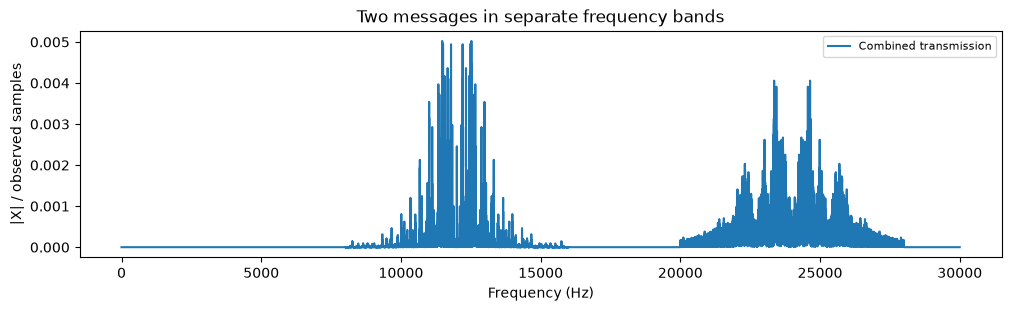

Combined transmission


In [16]:
# Add the two transmitted signals to form one shared signal.
combined = channels[0] + channels[1]
fig, ax = plt.subplots(figsize=(10, 3), constrained_layout=True)
lab.spectrum(ax, combined, fs, "Combined transmission")
ax.set_title("Two messages in separate frequency bands")
plt.show()
lab.listen({"Combined transmission": combined}, fs)

**Observations**

- The combined DFT shows **two separate humps**: 8–16 kHz (music) and 20–28 kHz (dialogue), with a gap of empty spectrum between them (16–20 kHz) and nothing below 8 kHz. Adding signals in time adds their spectra (linearity), and since the spectra don't overlap, each message is still intact in its own band. Played back, it sounds like high-pitched hiss — nothing recognisable (and much of it is beyond human hearing).
- **To recover one:** apply a **bandpass filter** around that carrier (e.g. 8–16 kHz for music, 20–28 kHz for dialogue) to throw away the other channel, then **multiply by the same carrier again** to shift it back down to 0–4 kHz, and **lowpass** to remove the copy that lands at $2f_c$. That is exactly what the next cells do.

Next, we will use our bandpass filter to extract a single component of the modulated signal. A bandpass filter with band $8000\text{Hz} - 16000\text{Hz}$ recovers the modulated music signal. Meanwhile, a bandpass filter with band $20000\text{Hz} - 28000\text{Hz}$ recovers the modulated dialogue signal.

**Optional:** To recover the original signal from the modulated signal, we multiply the modulated signal with the carrier signal again. This shifts a copy of the message back to its original low-frequency band which can then be extracted with another bandpass or lowpass filter.

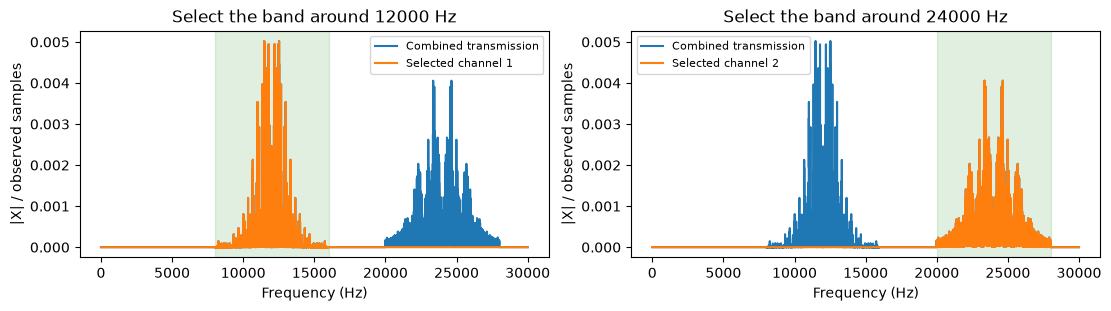

In [17]:
# Select each channel with a bandpass filter.
band_half_width = 4000  # Hz on either side of each carrier
selected_channels = [
    lab.fft_filter(combined, fs, fc - band_half_width, fc + band_half_width)
    for fc in carrier_frequencies
]
fig, axes = plt.subplots(1, 2, figsize=(11, 3), constrained_layout=True)
for j, (ax, fc) in enumerate(zip(axes, carrier_frequencies)):
    lab.spectrum(ax, combined, fs, "Combined transmission")
    lab.spectrum(ax, selected_channels[j], fs, "Selected channel %d" % (j + 1))
    ax.axvspan(fc - band_half_width, fc + band_half_width, alpha=0.12, color="green")
    ax.set_title("Select the band around %g Hz" % fc)
plt.show()

In [18]:
# Multiply by the same carrier again to shift the message back to low frequencies.
# The factor 2 restores the original amplitude; lowpass filtering removes the high frequencies.
mixed_messages = [
    2 * selected * carrier for selected, carrier in zip(selected_channels, carriers)
]
recovery_cutoff = 4000  # Hz
recovered_messages = [lab.fft_filter(mixed, fs, 0, recovery_cutoff) for mixed in mixed_messages]

In [19]:
# Listen at one shared playback gain; compare recovery with what was transmitted.
lab.listen({
    "Input message 1": messages[0], "Recovered message 1": recovered_messages[0],
    "Input message 2": messages[1], "Recovered message 2": recovered_messages[1],
}, fs)

Input message 1


Recovered message 1


Input message 2


Recovered message 2


**Q4B Questions**

- What property should the carrier frequencies satisfy for this method to be effective? *Hint:* This depends on the bandlimits of the input signal
- Suppose we wanted to transmit signals with larger bandlimit (For example, with higher frequencies). How should we change our carrier signals to accommodate them?

**Q4B Answers**

The recovered messages match the originals essentially perfectly here (relative error $\approx 2\times10^{-11}$, correlation 1.000000).

- **Required property:** if each message has bandlimit $B$ (here $B = 4$ kHz), each modulated channel occupies $[f_c - B,\, f_c + B]$ — width $2B$. The bands must not overlap, so
  $$|f_{c1} - f_{c2}| \ge 2B \quad(\text{here } \ge 8\text{ kHz; we used } 12\text{ kHz}).$$
  Also each $f_c \ge B$ (so the lower sideband doesn't fold through 0 Hz) and $f_c + B < f_s/2$ (Nyquist — this is why $f_s = 60$ kHz: $24 + 4 = 28 < 30$ kHz).
  *Checked:* with carriers 12 kHz and 16 kHz (only 4 kHz apart) the bands overlap and recovered message 1 is garbage (relative error 0.82); with both at 12 kHz it is mostly a mix of the two messages.
- **Larger bandlimit $B$:** **space the carriers further apart** (at least $2B$, ideally with a guard band), widen each bandpass to $f_c \pm B$ and the recovery lowpass to $B$, and move the carriers up as needed — which in turn means a **higher sampling rate** so $f_{c,\max} + B < f_s/2$. In real radio this is the trade-off of **frequency-division multiplexing**: more bandwidth per station = fewer stations fit in the spectrum (AM stations carry ~5 kHz audio and are spaced 9–10 kHz apart; FM uses ~200 kHz per station for higher-fidelity audio).